<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_4_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Görüntü İşleme ve Kenar Algılama Çalışması

Bu notebook içerisinde aşağıdaki görevler konu anlatımlı kod blokları ile sırasıyla uygulanacaktır:
- **Task 1 & 2:** Dikey ve Yatay Prewitt Filtreleri
- **Task 3:** Dikey ve Yatay Sobel Filtreleri
- **Task 4:** Prewitt vs Sobel Karşılaştırma Raporu
- **Task 5:** 3x3 Laplacian Çekirdeği
- **Task 6:** 7x7 Laplacian of Gaussian (LoG)
- **Task 7:** OpenCV Canny Algoritması ve Performans Karşılaştırması
- **Task 8:** Sıfırdan Adım Adım Canny Kenar Algılama

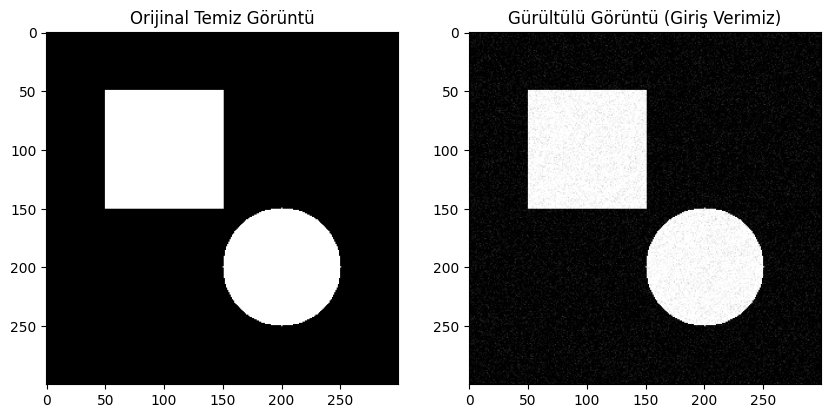

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Test için sentetik bir görüntü oluşturalım (daire ve kare içeren net kenarlı bir resim)
image_size = (300, 300)
img = np.zeros(image_size, dtype=np.uint8)

# Geometrik şekiller çizelim
cv2.rectangle(img, (50, 50), (150, 150), 255, -1)
cv2.circle(img, (200, 200), 50, 255, -1)

# Gürültü ekleyelim (filtrelerin etkisini görebilmek için)
np.random.seed(42)
noise = np.random.normal(0, 15, image_size).astype(np.int16)
noisy_img = np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Orijinal Temiz Görüntü")
plt.imshow(img, cmap='gray')
plt.subplot(1, 2, 2)
plt.title("Gürültülü Görüntü (Giriş Verimiz)")
plt.imshow(noisy_img, cmap='gray')
plt.show()

## Task 1 & Task 2: Prewitt Filtreleri (Dikey ve Yatay)

**Konu Anlatımı:**
Prewitt operatörü, yatay ve dikey yöndeki yoğunluk değişimlerini (gradyanları) hesaplamak için kullanılır.
- Dikey Kenar Dedektörü (Task 1):
  $$P_y = \begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix}$$
- Yatay Kenar Dedektörü (Task 2):
  $$P_x = \begin{bmatrix} -1 & -1 & -1 \\ 0 & 0 & 0 \\ 1 & 1 & 1 \end{bmatrix}$$

Öncelikle görüntüyü hafifçe yumuşatmak için 3x3 boyutunda bir Gauss Filtresi uyguluyoruz. Bu, gürültünün kenar olarak algılanmasını engeller.

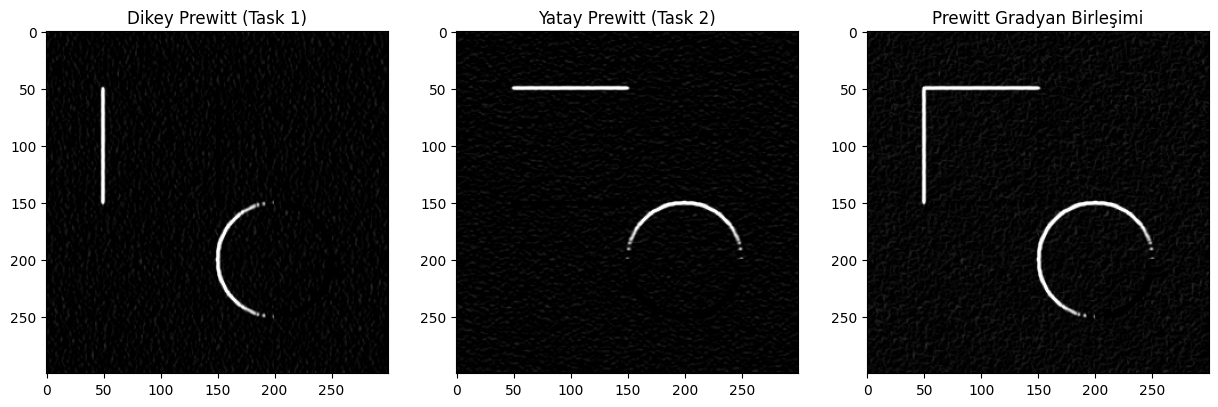

In [ ]:
# 1. Gauss Filtresi ile hafif yumuşatma (Yumuşatılmış Görüntü)
blurred_img = cv2.GaussianBlur(noisy_img, (3, 3), 0)

# Prewitt Kernelleri
kernel_prewitt_vertical = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
kernel_prewitt_horizontal = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)

# Filtrelerin Uygulanması
prewitt_v = cv2.filter2D(blurred_img, -1, kernel_prewitt_vertical)
prewitt_h = cv2.filter2D(blurred_img, -1, kernel_prewitt_horizontal)

# Kombine Prewitt (Bileşke Gradyan Magnitüdü)
prewitt_grad = np.sqrt(prewitt_v.astype(np.float32)**2 + prewitt_h.astype(np.float32)**2)
prewitt_grad = np.clip(prewitt_grad, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.title("Dikey Prewitt (Task 1)")
plt.imshow(prewitt_v, cmap='gray')
plt.subplot(1, 3, 2)
plt.title("Yatay Prewitt (Task 2)")
plt.imshow(prewitt_h, cmap='gray')
plt.subplot(1, 3, 3)
plt.title("Prewitt Gradyan Birleşimi")
plt.imshow(prewitt_grad, cmap='gray')
plt.show()

## Task 3: Sobel Filtresi (3x3 Dikey ve Yatay)

**Konu Anlatımı:**
Sobel filtresi, Prewitt ile benzer mantıkta çalışır ancak merkezdeki piksellere daha fazla ağırlık vererek (yumuşatma etkisi katarak) gürültüye karşı biraz daha dirençli olmasını sağlar.
- Dikey Sobel Kernel:
  $$S_y = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$$
- Yatay Sobel Kernel:
  $$S_x = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}$$

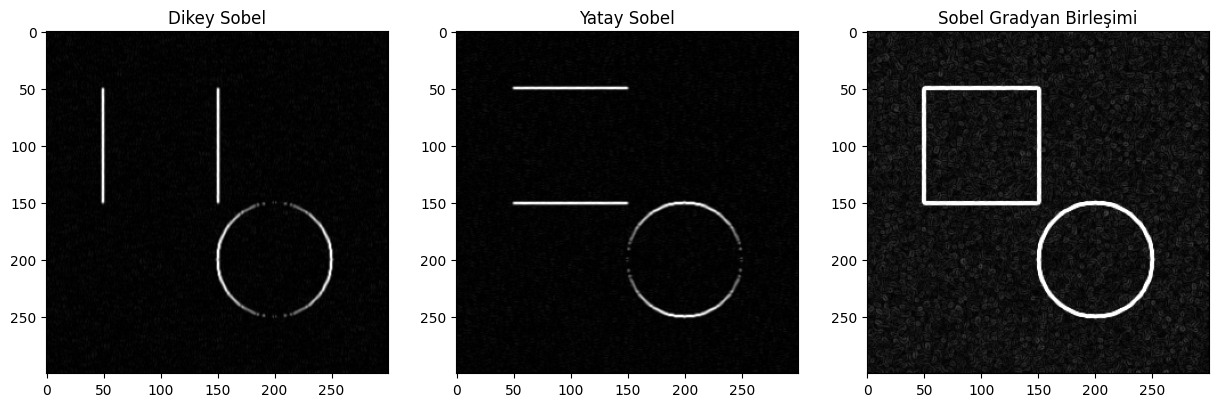

In [ ]:
# Sobel Filtrelerinin Tanımlanması ve Uygulanması
# OpenCV içindeki yerleşik cv2.Sobel fonksiyonu da kullanılabilir, özel filtre ile de yapılabilir.
sobel_v = cv2.Sobel(blurred_img, cv2.CV_64F, 1, 0, ksize=3)
sobel_h = cv2.Sobel(blurred_img, cv2.CV_64F, 0, 1, ksize=3)

# Gradyan büyüklüğü
sobel_grad = np.sqrt(sobel_v**2 + sobel_h**2)
sobel_grad = np.clip(sobel_grad, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.title("Dikey Sobel")
plt.imshow(np.abs(sobel_v), cmap='gray')
plt.subplot(1, 3, 2)
plt.title("Yatay Sobel")
plt.imshow(np.abs(sobel_h), cmap='gray')
plt.subplot(1, 3, 3)
plt.title("Sobel Gradyan Birleşimi")
plt.imshow(sobel_grad, cmap='gray')
plt.show()

## Task 4: Sobel ve Prewitt Karşılaştırması

```markdown
SOBEL VE PREWITT OPERATÖRLERİ KARŞILAŞTIRMA RAPORU

1. Teorik Farklar:
   - Her iki operatör de görüntü gradyanlarını hesaplayarak birinci türev tabanlı kenar tespiti yapar.
   - Prewitt, kenar piksellerine eşit ağırlık verirken; Sobel merkezdeki piksellere 2 kat fazla ağırlık vererek yerel düzgünleştirme (smoothing) uygular.

2. Gürültü Toleransı:
   - Sobel filtresi, katsayıları sayesinde gürültüyü baskılamada Prewitt'e kıyasla daha başarılıdır.
   - Prewitt filtresi gürültüden daha hızlı etkilenir ve yalancı kenarlar üretebilir.

3. Kenar Netliği:
   - Prewitt filtreleri gürültüsüz ortamlarda çok ince ve keskin sınırlar yakalayabilir.
   - Sobel filtreleri ise yumuşatıcı etkisiyle daha kalın ama daha kararlı kenar çizgileri sunar.
```

## Task 5: 3x3 Laplacian Filtresi ve Karşılaştırma

**Konu Anlatımı:**
Laplacian, ikinci türev tabanlı izotropik bir filtredir. Yön bağımsız çalışır ve tek bir matris ile kenarları bulabilir. Ancak ikinci türev gürültüye karşı aşırı duyarlıdır. Bu yüzden Gauss ile ön yumuşatma hayati önem taşır.
- Laplacian Kernel:
  $$L = \begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix} \quad \text{veya} \quad \begin{bmatrix} 1 & 1 & 1 \\ 1 & -8 & 1 \\ 1 & 1 & 1 \end{bmatrix}$$

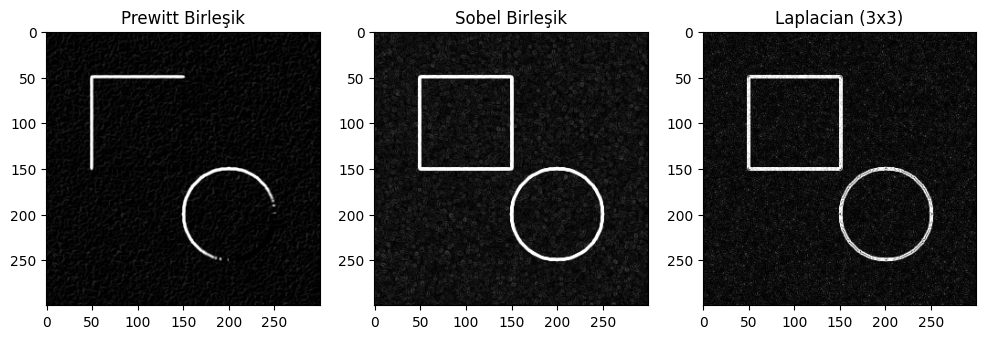

In [ ]:
# Laplacian Filtresi Uygulama
laplacian = cv2.Laplacian(blurred_img, cv2.CV_64F, ksize=3)
laplacian_abs = np.clip(np.abs(laplacian), 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.title("Prewitt Birleşik")
plt.imshow(prewitt_grad, cmap='gray')
plt.subplot(1, 3, 2)
plt.title("Sobel Birleşik")
plt.imshow(sobel_grad, cmap='gray')
plt.subplot(1, 3, 3)
plt.title("Laplacian (3x3)")
plt.imshow(laplacian_abs, cmap='gray')
plt.show()

## Task 6: 7x7 Laplacian of Gaussian (LoG)

**Konu Anlatımı:**
LoG, görüntüye doğrudan Gauss uygulayıp ardından Laplacian uygulamakla eşdeğerdir. Bu işlem tek bir matematiksel formüle dökülerek bir LoG filtresi matrisi oluşturulabilir.

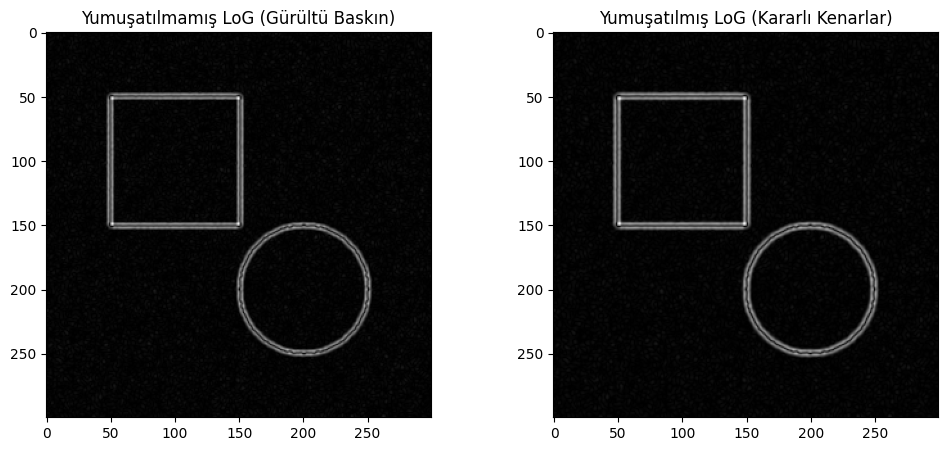

In [ ]:
# 7x7 boyutunda LoG kernel oluşturma
def create_log_kernel(size=7, sigma=1.4):
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = -1 / (np.pi * sigma**4) * (1 - (xx**2 + yy**2) / (2 * sigma**2)) * np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel - np.mean(kernel) # Sıfır toplamlı yapmak için normalize edilir

log_kernel = create_log_kernel(7, 1.4)

# Orijinal (Yumuşatılmamış) ve Yumuşatılmış görüntüler üzerinde test
log_without_blur = cv2.filter2D(noisy_img, cv2.CV_64F, log_kernel)
log_with_blur = cv2.filter2D(blurred_img, cv2.CV_64F, log_kernel)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.title("Yumuşatılmamış LoG (Gürültü Baskın)")
plt.imshow(np.abs(log_without_blur), cmap='gray')
plt.subplot(1, 2, 2)
plt.title("Yumuşatılmış LoG (Kararlı Kenarlar)")
plt.imshow(np.abs(log_with_blur), cmap='gray')
plt.show()

## Task 7: OpenCV Canny Kenar Tespiti ve Performans Analizi

**Konu Anlatımı:**
Canny, çok aşamalı yapısıyla kenar tespit algoritmaları içinde en başarılı olanlardandır. Diğer filtrelerle performansını kıyaslamak adına çalışma sürelerini ölçeceğiz.

Canny Çalışma Süresi: 5.4772 ms
Prewitt Filtreleme Süresi: 0.3614 ms


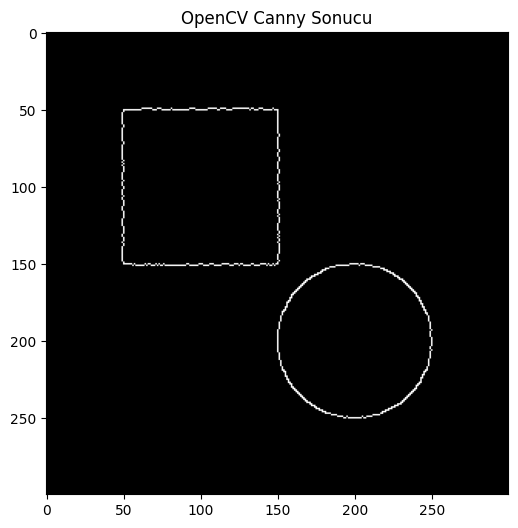

In [ ]:
# Zaman Ölçümü ve Canny Uygulama
t0 = time.time()
canny_edges = cv2.Canny(blurred_img, 50, 150)
t_canny = time.time() - t0

t0 = time.time()
_ = cv2.filter2D(blurred_img, -1, kernel_prewitt_vertical)
t_prewitt = time.time() - t0

print(f"Canny Çalışma Süresi: {t_canny*1000:.4f} ms")
print(f"Prewitt Filtreleme Süresi: {t_prewitt*1000:.4f} ms")

plt.figure(figsize=(6, 6))
plt.title("OpenCV Canny Sonucu")
plt.imshow(canny_edges, cmap='gray')
plt.show()

## Task 8: Sıfırdan Adım Adım Canny Kenar Dedektörü

Şimdi tüm alt fonksiyonları açıkça gösterecek şekilde Canny algoritmasını sıfırdan yazıyoruz.

In [ ]:
# 1. Gürültü Bastırma (5x5 Gauss Filtresi)
def gaussian_blur_5x5(img):
    kernel = np.array([
        [1,  4,  7,  4, 1],
        [4, 16, 26, 16, 4],
        [7, 26, 41, 26, 7],
        [4, 16, 26, 16, 4],
        [1,  4,  7,  4, 1]
    ], dtype=np.float32) / 273.0
    return cv2.filter2D(img, -1, kernel)

# 2. Sobel ile Gradyan Hesaplama
def sobel_gradients(img):
    # El ile 3x3 Sobel uyguluyoruz
    K_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
    K_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)

    I_x = cv2.filter2D(img, cv2.CV_32F, K_x)
    I_y = cv2.filter2D(img, cv2.CV_32F, K_y)

    G = np.hypot(I_x, I_y)
    G = G / G.max() * 255
    theta = np.arctan2(I_y, I_x)
    return G, theta

# 3. Non-maximum Suppression
def non_max_suppression(img, D):
    M, N = img.shape
    Z = np.zeros((M,N), dtype=np.int32)
    angle = D * 180. / np.pi
    angle[angle < 0] += 180

    for i in range(1, M-1):
        for j in range(1, N-1):
            q = 255
            r = 255

            # 0 Derece
            if (0 <= angle[i,j] < 22.5) or (157.5 <= angle[i,j] <= 180):
                q = img[i, j+1]
                r = img[i, j-1]
            # 45 Derece
            elif (22.5 <= angle[i,j] < 67.5):
                q = img[i+1, j-1]
                r = img[i-1, j+1]
            # 90 Derece
            elif (67.5 <= angle[i,j] < 112.5):
                q = img[i+1, j]
                r = img[i-1, j]
            # 135 Derece
            elif (112.5 <= angle[i,j] < 157.5):
                q = img[i-1, j-1]
                r = img[i+1, j+1]

            if (img[i,j] >= q) and (img[i,j] >= r):
                Z[i,j] = img[i,j]
            else:
                Z[i,j] = 0
    return Z

# 4. Hysteresis Thresholding
def threshold_and_hysteresis(img, lowThresholdRatio=0.05, highThresholdRatio=0.09):
    highThreshold = img.max() * highThresholdRatio
    lowThreshold = highThreshold * lowThresholdRatio

    M, N = img.shape
    res = np.zeros((M,N), dtype=np.int32)

    weak = np.int32(25)
    strong = np.int32(255)

    strong_i, strong_j = np.where(img >= highThreshold)
    zeros_i, zeros_j = np.where(img < lowThreshold)

    weak_i, weak_j = np.where((img >= lowThreshold) & (img <= highThreshold))

    res[strong_i, strong_j] = strong
    res[weak_i, weak_j] = weak

    # Hysteresis Takibi
    for i in range(1, M-1):
        for j in range(1, N-1):
            if (res[i,j] == weak):
                if ((res[i+1, j-1] == strong) or (res[i+1, j] == strong) or (res[i+1, j+1] == strong)
                    or (res[i, j-1] == strong) or (res[i, j+1] == strong)
                    or (res[i-1, j-1] == strong) or (res[i-1, j] == strong) or (res[i-1, j+1] == strong)):
                    res[i, j] = strong
                else:
                    res[i, j] = 0
    return res

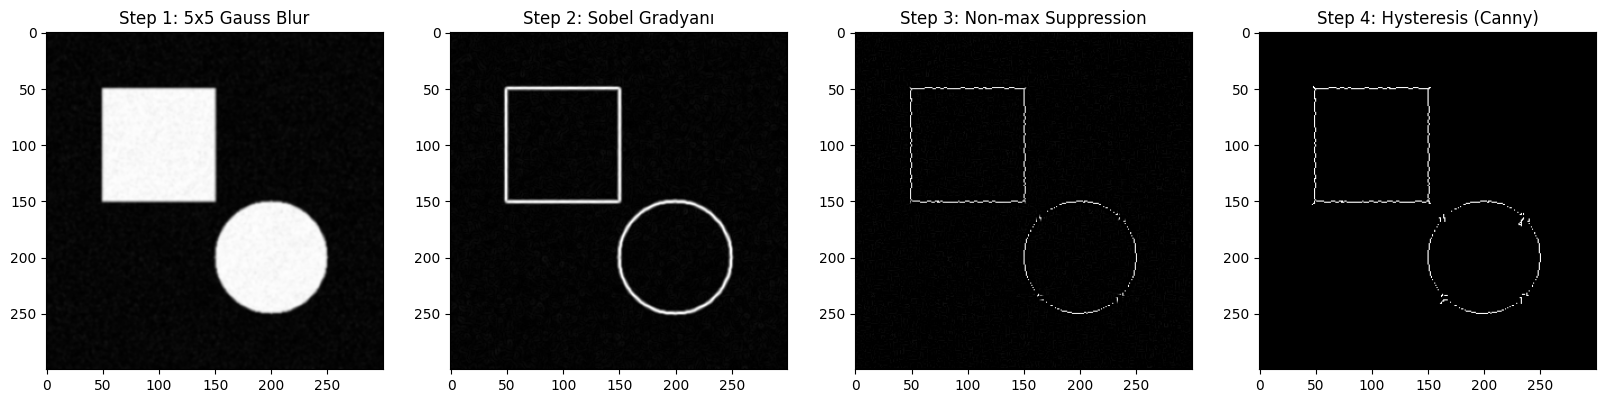

In [ ]:
# Adım Adım Pipeline'ı Test Edelim
step1 = gaussian_blur_5x5(noisy_img)
step2_G, step2_theta = sobel_gradients(step1)
step3 = non_max_suppression(step2_G, step2_theta)
step4 = threshold_and_hysteresis(step3, 0.05, 0.15)

plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.title("Step 1: 5x5 Gauss Blur")
plt.imshow(step1, cmap='gray')
plt.subplot(1, 4, 2)
plt.title("Step 2: Sobel Gradyanı")
plt.imshow(step2_G, cmap='gray')
plt.subplot(1, 4, 3)
plt.title("Step 3: Non-max Suppression")
plt.imshow(step3, cmap='gray')
plt.subplot(1, 4, 4)
plt.title("Step 4: Hysteresis (Canny)")
plt.imshow(step4, cmap='gray')
plt.show()